# CA1 Data Preparation Module - sba26096 -Ciaran Lynch

## Data Preparation

### Add python libraries to analysis

In [197]:
import pandas as pd
import seaborn as sns
%matplotlib inline  
import matplotlib.pyplot as plt
import numpy as np


The assignment requires us to carried out analysis of a csv named student_dataV2
A student_data_Dictionary excel file was also attached for reference.  I have saved the data Dictionary to a a txt file.  See information below
This file gives us a description of the variable names listed and their associate meaning.  
It is also important to note that the Target states "The problem is formulated as a three category classification task (dropout, enrolled, and graduate) at the end of the normal duration of the course".  
Therefore enrolled was a result at the end of the course and does not infer that this is current students, awaiting results

In [198]:
with open("Data_Dictionary.txt","r") as f:
    print(f.read())

Courses
33:	"Biofuel Production Technologies",
171:	"Animation and Multimedia Design",
8014:	"Social Service (evening attendance)",
9003:	"Agronomy",
9070:	"Communication Design",
9085:	"Veterinary Nursing",
9119: 	"Informatics Engineering",
9130: 	"Equinculture",
9147: 	"Management",
9238:	"Social Service",
9254:	 "Tourism",
9500: 	"Nursing", 
9556: 	"Oral Hygiene",
9670: 	"Advertising and Marketing Management",
9773: 	"Journalism and Communication",
9853:  "Basic Education",
9991: 	"Management (evening attendance)",
9999:  "Unknown"



Qualifications


1  : "Secondary Education : 12th Year of Schooling or Eq",
2  : "Higher Education : Bachelor's Degree",
3  : "Higher Education : Degree",
4  : "Higher Education : Master's ",
5  : "Higher Education : Doctorate", 
6  : "Frequency of Higher Education",
9 : "12th Year of Schooling : Not Completed",
10 : "11th Year of Schooling : Not Completed",
11 : "7th Year (Old)",
12  : "Other : 11th Year of Schooling",
13 : " 2nd year complementary hi

Load the Dataset provided called student_dataV2

In [199]:
df = pd.read_csv("student_dataV2.csv")

### Characterisation of the data set

Check  the data loaded correctly

In [200]:
df.head(5)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,...,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,...,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,...,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17.0,2.0,9773.0,1,1,122.0,1,38,37.0,...,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39.0,1.0,8014.0,0,1,100.0,1,37,38.0,...,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [201]:
df.shape

(4424, 37)

In [202]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   object 
 1   Application mode                                4423 non-null   float64
 2   Application order                               4423 non-null   float64
 3   Course                                          4421 non-null   float64
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4420 non-null   float64
 7   Nacionality                                     4424 non-null   object 
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

We can see that the dataset contains 4424 rows of data and  37 columns and we have a target categorical variable, from the data dictionary, it should be 3 values of "Graduate", "Dropout" and "Enrolled".  
From the table information, we have 8 Objects (String values), 15 Float values (2 decimal points) and 14 Integer values.  
Gender is also listed as numeric where 1=male and 0=female and listed as integer, is this for correlation purposes?

Maritial Status values are from 1-6, but it is also listed as an object

#### 1. Rename the columns to make it more readable and code friendly

In [203]:
df = df.rename(columns={
    "Marital status": "maritial_status",
    "Application mode": "application_mode",
    "Application order": "application_order",
    "Course": "course_no",
    "Daytime/evening attendance": "course_time",
    "Previous qualification": "previous_qual",
    "Previous qualification (grade)": "previous_grade",
    "Nacionality": "nacionality",
    "Mother's qualification": "mothers_qual",
    "Father's qualification": "fathers_qual",
    "Mother's occupation": "mothers_occupation",
    "Father's occupation": "fathers_occupation",
    "Admission grade": "admission_grade",
    "Educational special needs": "special_needs",
    "Debtor": "debtor",
    "Tuition fees up to date": "tuition_paid",
    "Gender": "gender",
    "Scholarship holder" : "scholarship_holder",
    "Age at enrollment": "enrollment_age",
    "International": "international",
    "Curricular units 1st sem (credited)": "1st_sem_credit",
    "Curricular units 1st sem (enrolled)": "1st_sem_enrolled",
    "Curricular units 1st sem (evaluations)": "1st_sem_evaluation",
    "Curricular units 1st sem (approved)": "1st_sem_approved",
    "Curricular units 1st sem (grade)": "1st_sem_grade",
    "Curricular units 1st sem (without evaluations)": "1st_sem_without_eval",
    "Curricular units 2nd sem (credited)": "2nd_sem_credit",
    "Curricular units 2nd sem (enrolled)": "2nd_sem_enrolled",
    "Curricular units 2nd sem (evaluations)": "2nd_sem_evaluation",
    "Curricular units 2nd sem (approved)": "2nd_sem_approved",
    "Curricular units 2nd sem (grade)": "2nd_sem_grade",
    "Curricular units 2nd sem (without evaluations)": "2nd_sem_without_eval",
    "Unemployment rate": "unemployed_rate",
    "Inflation rate": "inflation_rate"
    } 
    )

#### 2. Some of these columns need to be updated to Integer values

In [204]:
# create a list of columns that require transformation to integer
columns_convert = [
    "fathers_occupation",
    "mothers_occupation",
    "maritial_status",
    "course_no",
    "enrollment_age",
    "tuition_paid",
    "international",
    "1st_sem_credit",
    "nacionality",
    "application_mode",
    "application_order",
    "fathers_qual",
    "debtor"
]


df[columns_convert] = df[columns_convert].apply(pd.to_numeric, errors="coerce").astype("Int64")
    

In [205]:
df[columns_convert].dtypes

fathers_occupation    Int64
mothers_occupation    Int64
maritial_status       Int64
course_no             Int64
enrollment_age        Int64
tuition_paid          Int64
international         Int64
1st_sem_credit        Int64
nacionality           Int64
application_mode      Int64
application_order     Int64
fathers_qual          Int64
debtor                Int64
dtype: object

source:  https://www.codegenes.net/blog/batch-convert-columns-to-numeric-type/

In [206]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   maritial_status       4423 non-null   Int64  
 1   application_mode      4423 non-null   Int64  
 2   application_order     4423 non-null   Int64  
 3   course_no             4421 non-null   Int64  
 4   course_time           4424 non-null   int64  
 5   previous_qual         4424 non-null   int64  
 6   previous_grade        4420 non-null   float64
 7   nacionality           4423 non-null   Int64  
 8   mothers_qual          4424 non-null   int64  
 9   fathers_qual          4423 non-null   Int64  
 10  mothers_occupation    4423 non-null   Int64  
 11  fathers_occupation    4422 non-null   Int64  
 12  admission_grade       4422 non-null   float64
 13  Displaced             4424 non-null   object 
 14  special_needs         4424 non-null   int64  
 15  debtor               

Evaluate missing rows

In [207]:
df.isnull().sum()

maritial_status         1
application_mode        1
application_order       1
course_no               3
course_time             0
previous_qual           0
previous_grade          4
nacionality             1
mothers_qual            0
fathers_qual            1
mothers_occupation      1
fathers_occupation      2
admission_grade         2
Displaced               0
special_needs           0
debtor                  1
tuition_paid            2
gender                  0
scholarship_holder      0
enrollment_age          2
international           1
1st_sem_credit          1
1st_sem_enrolled        0
1st_sem_evaluation      0
1st_sem_approved        0
1st_sem_grade           1
1st_sem_without_eval    0
2nd_sem_credit          0
2nd_sem_enrolled        1
2nd_sem_evaluation      0
2nd_sem_approved        0
2nd_sem_grade           1
2nd_sem_without_eval    0
unemployed_rate         0
inflation_rate          0
GDP                     0
Target                  0
dtype: int64

In [208]:
# Create a function to show percentage of missing data
# and show only those with missing data
def percent_missing(df):
    percent_nan = 100* df.isnull().sum() / len(df) # find % by dividing missing rows with length of dataframe
    percent_nan = percent_nan[percent_nan>0].sort_values() # missing data only ie >0 and sort
    return percent_nan

In [209]:
percent_nan = percent_missing(df)
percent_nan

maritial_status       0.022604
1st_sem_grade         0.022604
1st_sem_credit        0.022604
international         0.022604
debtor                0.022604
2nd_sem_enrolled      0.022604
mothers_occupation    0.022604
2nd_sem_grade         0.022604
nacionality           0.022604
application_order     0.022604
application_mode      0.022604
fathers_qual          0.022604
admission_grade       0.045208
tuition_paid          0.045208
enrollment_age        0.045208
fathers_occupation    0.045208
course_no             0.067812
previous_grade        0.090416
dtype: float64

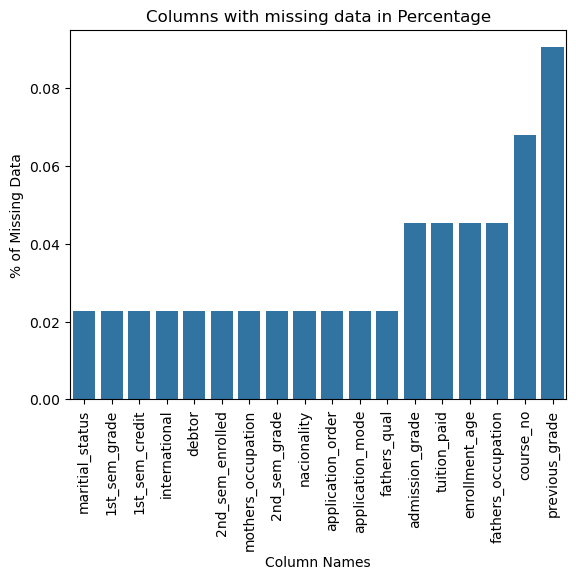

In [210]:
sns.barplot(x=percent_nan.index,
            y=percent_nan)
plt.xticks(rotation=90);

plt.title("Columns with missing data in Percentage")
plt.xlabel("Column Names")
plt.ylabel("% of Missing Data")

plt.show()

source: https://www.udemy.com/course/python-for-machine-learning-data-science-masterclass/learn/lecture/23121514#overview.  

A quick check of missing data shows 27 missing rows from 4424.  This represents 0.47% of the total rows. I will carry out an analysis of those missing rows in this review.

#### Updating Variables

I will create map values for variables columns.  This information has been taken from the data dictionary provided.  
The purpose of this is to create a information column for some of the numeric codes, for readability purposes, especially for showing charts. graphs, etc.  However the numerical values were kept, as they may be requitred for correlation, PCA analysis.
    
"Previous Qualification", "Mothers Qualification" and "Fathers Qualification" is essentially reading from the same data dictionary information and can be updated using the "parents_qual_map" created below.  
Mothers and fathers occupation are also codes for a occupation list that could be merged.
    


#### See course map below, 
For course info, add in 9999 - "Unknown".  This will allow me to update any nan values, as opposed to simply removing them.  


The parents_qual_map was created by merging the information from mothers, fathers and previous qualifications.  
    
Info columns have been created from these maps, to include descriptive information from the various numeric codes.  
    
There are a few variables that I kept as integer values such as gender, international, course_time, as they are 1 or 0.  
    
Those were kept in case there is a correlation / PCA need for them to be numerical binary values.  


In [211]:
# add course information, add in 9999 - unknown for nan values
course_map = {
     33:	"Biofuel Production Technologies",
     171:	"Animation and Multimedia Design",
     8014:	"Social Service (evening attendance)",
     9003:	"Agronomy",
     9070:	"Communication Design",
     9085:	"Veterinary Nursing",
     9119: 	"Informatics Engineering",
     9130: 	"Equinculture",
     9147: 	"Management",
     9238:	"Social Service",
     9254:	 "Tourism",
     9500: 	"Nursing", 
     9556: 	"Oral Hygiene",
     9670: 	"Advertising and Marketing Management",
     9773: 	"Journalism and Communication",
     9853:  "Basic Education",
     9991: 	"Management (evening attendance)",
     9999:  "Unknown"
}



 
# Per review of data Dictionary, both mothers Qualification, Fathers Qualification and previous_qualification 
# variables are basically same values, although a no15 category was merged in from previous qualification.
parents_qual_map = {
        1  : "Secondary Education - 12th Year of Schooling or Eq",
        2  : "Higher Education - Bachelor's Degree",
        3  : "Higher Education - Degree",
        4  : "Higher Education - Master's ",
        5  : "Higher Education - Doctorate",
        6  : "Frequency of Higher Education",
        9 : "12th Year of Schooling - Not Completed",
        10 : "11th Year of Schooling - Not Completed",
        11 : "7th Year (Old)",
        12  : "Other - 11th Year of Schooling",
        13 : " 2nd year complementary high school course",
        14  : "10th Year of Schooling",
        15 : "10th year of schooling - not completed",
        18 : "General commerce course",
        19  : "Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv",
        20  : "Complementary High School Course",
        22  : "Technical-professional course",
        25 : "Complementary High School Course - not concluded",
        26  : "7th year of schooling",
        27 : "2nd cycle of the general high school course",
        29 : "9th Year of Schooling - Not Completed",
        30 : "8th year of schooling",
        31  : "General Course of Administration and Commerce",
        33 : "Supplementary Accounting and Administration",
        34 : "Unknown",
        35 : "Can't read or write",
        36 : "Can read without having a 4th year of schooling ",
        37 : "Basic education 1st cycle (4th/5th year) or equiv",
        38 : "Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv",
        39 : "Technological specialization course",
        40 : "Higher education - degree (1st cycle)",
        41 : "Specialized higher studies course",
        42 : "Professional higher technical course",
        43 : "Higher Education - Master (2nd cycle)",
        44 : "Higher Education - Doctorate (3rd cycle)"
}

# Add a map for nationality, currently listed as an object, so put quotation marks on the numbers
nationality_map = {
        1  : "Portuguese",
        2 : "German",
        6 : "Spanish;",
        11 : "Italian;",
        13  : "Dutch",
        14 : "English",
        17 : "Lithuanian",
        21 : "Angolan",
        22 : "Cape Verdean",
        24 : "Guinean",
        25 : "Mozambican",
        26 : "Santomean",
        32 : "Turkish;",
        41 : "Brazilian",
        62 : " Romanian",
        100  : "Moldova (Republic of)",
        101  : "Mexican;",
        103  : "Ukrainian",
        105  : "Russian",
        108  : "Cuban",
        109  : "Colombia"
}

#add a parents occupation map
occupation_map = {
    0 : "Student",
    1 : "Representatives of the Legislative Power and Executive Bodies, Directors, Directors and Executive Managers",
    2 : "Specialists in Intellectual and Scientific Activities",
    3 : "Intermediate Level Technicians and Professions",
    4 : "Administrative staff", 
    5 : "Personal Services, Security and Safety Workers and Sellers",
    6 : "Farmers and Skilled Workers in Agriculture, Fisheries and Forestry",
    7 : "Skilled Workers in Industry, Construction and Craftsmen",
    8 : "Installation and Machine Operators and Assembly Workers",
    9 : "Unskilled Workers",
    10 : "Armed Forces Professions",
    90 : "Other Situation",
    99 : "blank",
    101 : "Armed Forces Officers",
    102 : "Armed Forces Sergeants",
    103 : "Other Armed Forces personnel",
    112 : "Directors of administrative and commercial services",
    114 : "Hotel, catering, trade and other services directors",
    121 : "Specialists in the physical sciences, mathematics, engineering and related techniques",
    122 : "Health professionals",
    123 : "Teachers",
    124 : "Specialists in finance, accounting, administrative organization, public and commercial relations",
    125 : "Specialists in information and communication technologies (ICT)",
    131 : "Intermediate level science and engineering technicians and professions",
    132 : "Technicians and professionals, of intermediate level of health",
    134 : "Intermediate level technicians from legal, social, sports, cultural and similar services",
    135 : "Information and communication technology technicians",
    141 : "Office workers, secretaries in general and data processing operators",
    143 : "Data, accounting, statistical, financial services and registry-related operators",
    144 : "Other administrative support staff",
    151 : "personal service workers",
    152 : "Sellers",
    153 : "Personal care workers and the like",
    154 : "Protection and security services personnel",
    161 : "Market-oriented farmers and skilled agricultural and animal production workers",
    163 : "Farmers, livestock keepers, fishermen, hunters and gatherers, subsistence",
    171 : "Skilled construction workers and the like, except electricians",
    172 : "Skilled workers in metallurgy, metalworking and similar",
    173 : "Skilled workers in printing, precision instrument manufacturing, jewelers, artisans and the like",
    174 : "Skilled workers in electricity and electronics",
    175 : "Workers in food processing, woodworking, clothing and other industries and crafts",
    181 : "Fixed plant and machine operators",
    182 : "Assembly workers",
    183 : "Vehicle drivers and mobile equipment operators",
    191 : "Cleaning workers",
    192 : "Unskilled workers in agriculture, animal production, fisheries and forestry",
    193 : "Unskilled workers in extractive industry, construction, manufacturing and transport",
    194 : "Meal preparation assistants",
    195 : "Street vendors (except food) and street service providers"

}



#### Assign the map values to corresponding columns

In [212]:
df["course_name"] = df["course_no"].map(course_map) 
df["mothers_qual_info"] = df["mothers_qual"].map(parents_qual_map)
df["fathers_qual_info"] = df["fathers_qual"].map(parents_qual_map)
df["previous_qual_info"] = df["previous_qual"].map(parents_qual_map)
df["nacionality_info"] = df["nacionality"].map(nationality_map)
df["mothers_occupation_info"] = df["mothers_occupation"].map(occupation_map)
df["fathers_occupation_info"] = df["fathers_occupation"].map(occupation_map)

In [213]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 44 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   maritial_status          4423 non-null   Int64  
 1   application_mode         4423 non-null   Int64  
 2   application_order        4423 non-null   Int64  
 3   course_no                4421 non-null   Int64  
 4   course_time              4424 non-null   int64  
 5   previous_qual            4424 non-null   int64  
 6   previous_grade           4420 non-null   float64
 7   nacionality              4423 non-null   Int64  
 8   mothers_qual             4424 non-null   int64  
 9   fathers_qual             4423 non-null   Int64  
 10  mothers_occupation       4423 non-null   Int64  
 11  fathers_occupation       4422 non-null   Int64  
 12  admission_grade          4422 non-null   float64
 13  Displaced                4424 non-null   object 
 14  special_needs           

Now that columns were added, the map values are in place, we have 27 Integers, 8 Floats = 35 numeric and 9 Objects.
The info objects have been added to have readability of the courses, qualifications, nationalities etc, but also to keep the numeric codes.  
Check head and tail to ensure data loaded correctly

In [214]:
df.head(3)

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,inflation_rate,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info
0,1,17,5,171,1,1,122.0,1,19,12,...,1.4,1.74,Dropout,Animation and Multimedia Design,Basic Education 3rd Cycle (9th/10th/11th Year)...,Other - 11th Year of Schooling,Secondary Education - 12th Year of Schooling o...,Portuguese,"Personal Services, Security and Safety Workers...",Unskilled Workers
1,1,15,1,9254,1,1,160.0,1,1,3,...,-0.3,0.79,Graduate,Tourism,Secondary Education - 12th Year of Schooling o...,Higher Education - Degree,Secondary Education - 12th Year of Schooling o...,Portuguese,Intermediate Level Technicians and Professions,Intermediate Level Technicians and Professions
2,1,1,5,9070,1,1,122.0,1,37,37,...,1.4,1.74,Dropout,Communication Design,Basic education 1st cycle (4th/5th year) or equiv,Basic education 1st cycle (4th/5th year) or equiv,Secondary Education - 12th Year of Schooling o...,Portuguese,Unskilled Workers,Unskilled Workers


In [215]:
df.tail(3)

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,inflation_rate,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info
4421,1,1,1,9500,1,1,154.0,1,37,37,...,-0.3,0.79,Dropout,Nursing,Basic education 1st cycle (4th/5th year) or equiv,Basic education 1st cycle (4th/5th year) or equiv,Secondary Education - 12th Year of Schooling o...,Portuguese,Unskilled Workers,Unskilled Workers
4422,1,1,1,9147,1,1,180.0,1,37,37,...,-0.8,-3.12,Graduate,Management,Basic education 1st cycle (4th/5th year) or equiv,Basic education 1st cycle (4th/5th year) or equiv,Secondary Education - 12th Year of Schooling o...,Portuguese,"Skilled Workers in Industry, Construction and ...",Administrative staff
4423,1,10,1,9773,1,1,152.0,22,38,37,...,3.7,-1.70,Graduate,Journalism and Communication,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Basic education 1st cycle (4th/5th year) or equiv,Secondary Education - 12th Year of Schooling o...,Cape Verdean,"Personal Services, Security and Safety Workers...",Unskilled Workers


#### 3. Check for duplicate rows

In [216]:
duplicateRows = df[df.duplicated()]
print("The number of duplicate rows = ", len(duplicateRows))

The number of duplicate rows =  0


No duplicate rows found in the data set

### Analysis of columns

#### 4.  Carry out analysis of the Target Column
This is an important variable, used for modelling, it should have 3 categories only

In [217]:
df["Target"].unique()

array(['Dropout', 'Graduate', 'Enrolled', 'Grad', 'graduate', 'Drop',
       'dropout'], dtype=object)

From review of the unique rows, we can see errors in categorising the values, showing incorrect wording, ie Grad instead of Graduate
These need to be replaced, by using the .replace method, to take it to 3 variables only

In [218]:
df["Target"] = df["Target"].replace(
    {
        "Grad": "Graduate",
        "graduate": "Graduate",
        "Drop" : "Dropout",
        "dropout": "Dropout"
    }
)

In [219]:
df["Target"].unique()

array(['Dropout', 'Graduate', 'Enrolled'], dtype=object)

In [220]:
df["Target"].value_counts()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

<Axes: xlabel='Target'>

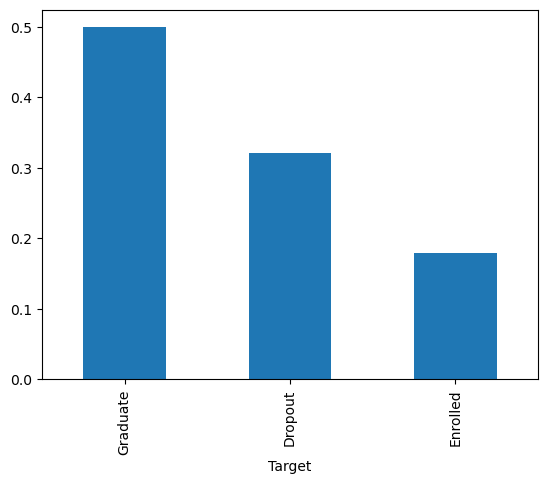

In [221]:
df["Target"].value_counts(normalize=True).plot.bar()

The Target variable is now correctly updated

#### ****

#### 5. Carry out analysis of course information

In [222]:
df["course_no"].unique()

<IntegerArray>
[ 171, 9254, 9070, 9773, 8014, 9991, 9500, 9238, 9670, 9853, 9085, 9130, 9556,
 9147, 9003,   33, 9119, <NA>]
Length: 18, dtype: Int64

We have some nan missing values for course information.  
Check below for information on those missing values

In [223]:
df[df["course_no"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,inflation_rate,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info
649,1,1,1,<NA>,1,1,117.0,1,1,38,...,-0.8,-3.12,Graduate,NaN,Secondary Education - 12th Year of Schooling o...,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Secondary Education - 12th Year of Schooling o...,Portuguese,"Personal Services, Security and Safety Workers...",Representatives of the Legislative Power and E...
3681,5,39,1,<NA>,1,1,133.1,1,19,19,...,0.6,2.02,Enrolled,NaN,Basic Education 3rd Cycle (9th/10th/11th Year)...,Basic Education 3rd Cycle (9th/10th/11th Year)...,Secondary Education - 12th Year of Schooling o...,Portuguese,Unskilled Workers,Unskilled Workers
3823,1,<NA>,1,<NA>,1,39,130.0,1,38,19,...,0.6,2.02,Dropout,NaN,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Basic Education 3rd Cycle (9th/10th/11th Year)...,Technological specialization course,Portuguese,Unskilled Workers,Unskilled Workers


Fill the course as 9999 and the course_name as "Unknown"

In [224]:
df["course_no"] = df["course_no"].fillna(9999)

In [225]:
df["course_name"] = df["course_name"].fillna("Unknown")

In [226]:
df[df["course_no"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,inflation_rate,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info


In [227]:
# check to see if the record updated correctly
df.loc[ [649,3681, 3823], ["course_no", "course_name", "course_time"] ]

,course_no,course_name,course_time
649,9999,Unknown,1
3681,9999,Unknown,1
3823,9999,Unknown,1


In [228]:
df["course_no"].unique()

<IntegerArray>
[ 171, 9254, 9070, 9773, 8014, 9991, 9500, 9238, 9670, 9853, 9085, 9130, 9556,
 9147, 9003,   33, 9119, 9999]
Length: 18, dtype: Int64

#### Show results of course information

In [229]:
df[ ["course_no", "course_name", "course_time"] ].head(5)

,course_no,course_name,course_time
0,171,Animation and Multimedia Design,1
1,9254,Tourism,1
2,9070,Communication Design,1
3,9773,Journalism and Communication,1
4,8014,Social Service (evening attendance),0


In [230]:
df["course_name"].value_counts()

course_name
Nursing                                 766
Management                              379
Social Service                          355
Veterinary Nursing                      337
Journalism and Communication            331
Management (evening attendance)         268
Advertising and Marketing Management    267
Tourism                                 252
Communication Design                    226
Animation and Multimedia Design         215
Social Service (evening attendance)     215
Agronomy                                210
Basic Education                         192
Informatics Engineering                 170
Equinculture                            140
Oral Hygiene                             86
Biofuel Production Technologies          12
Unknown                                   3
Name: count, dtype: int64

There were 3 missing values for course information
Above, in the course map, i added a value of 9999 for Unknown for these 3 nan values, i imputed the record as "Unknown", as opposed to deleting 3 rows
All course information is updated and no missing values

####  ****

#### 6. Carry Out Analysis of Course Attendance time

In [231]:
df["course_time"].unique()

array([1, 0])

In [232]:
df["course_time"].value_counts()

course_time
1    3941
0     483
Name: count, dtype: int64

Show the same value counts of Attendance as a percentage, rounded to 2 decimals

In [233]:
round(df["course_time"].value_counts(normalize=True) * 100,2)

course_time
1    89.08
0    10.92
Name: proportion, dtype: float64

From the above value counts, we see that the majority of the students are daytime attenders with 89.08% attending a Daytime course.  
    
1 = Daytime course 
0 = Evening course.  
    
This is a category that could be categorical, but i am unsure about changing this, as it may be required as an Integer for correlation

#### ****

#### 7. Carry out analysis of gender variable.  

#### 1 = Male and 0 = Female

In [234]:
df["gender"].unique()

array([1, 0])

In [235]:
round(df["gender"].value_counts(normalize=True) * 100,2)

gender
0    64.83
1    35.17
Name: proportion, dtype: float64

No errors found in the gender analysis
We have a slightly higher Female representation at 64.83% of the Student population
This is another category that could be categorical, but again i am unsure about changing this

#### ****

#### 8. Carry out on maritial_status

In [236]:
df["maritial_status"].unique()

<IntegerArray>
[1, 2, 4, <NA>, 3, 5, 6]
Length: 7, dtype: Int64

We can see that more errors have been discovered, with nan values listed.  Check missing imformation

In [237]:
df[df["maritial_status"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,inflation_rate,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info
154,<NA>,43,1,9853,1,1,115.0,1,3,37,...,-0.8,-3.12,Dropout,Basic Education,Higher Education - Degree,Basic education 1st cycle (4th/5th year) or equiv,Secondary Education - 12th Year of Schooling o...,Portuguese,Specialists in Intellectual and Scientific Act...,"Personal Services, Security and Safety Workers..."


Only 1 field with Maritial Status incomplete.  This was a 21 year old local daytime student.  Not sure how relevent maritial stautus will be for analysis and for the sake of keeping the record, based on the students age, i will fill this as "single",given also that the vast majority of young daytime students are single

In [238]:
df["maritial_status"] = df["maritial_status"].fillna(1)

In [239]:
df["maritial_status"].unique()

<IntegerArray>
[1, 2, 4, 3, 5, 6]
Length: 6, dtype: Int64

In [240]:
df["maritial_status"].value_counts()

maritial_status
1    3919
2     379
4      91
5      25
6       6
3       4
Name: count, dtype: Int64

Show Maritial Status Table as a Percentage

In [241]:
round(df["maritial_status"].value_counts(normalize=True) * 100,2)

maritial_status
1    88.58
2     8.57
4     2.06
5     0.57
6     0.14
3     0.09
Name: proportion, dtype: Float64

From the above value counts, we can see that the vast majority of our students are single = 88.58%, this was the reasoning for imputing (1 = single) into the nan row

#### ****

### 9. Carry out analysis of enrollment_age

In [242]:
df["enrollment_age"].unique()

<IntegerArray>
[  20,   19,   45,   50,   18,   22,   21,   34,   37,   43,   55,   39,   29,
   24,   27,   23,   26,   33,   35,   25,   44,   36,   47,   28,   38, <NA>,
   30,   31,   32,   40,   42,   48,   49,   46,   41,   70,   60,   53,   51,
   52,   54,   61,   58,   59,   17,   57,   62]
Length: 47, dtype: Int64

More errors can be seen in the enrollment age.  See the presence of unknown, nan variables in the rows.  Replace unknown to nan using numpy

In [243]:
df["enrollment_age"] = df["enrollment_age"].replace("UnKnown", np.nan)

In [244]:
df["enrollment_age"].unique()

<IntegerArray>
[  20,   19,   45,   50,   18,   22,   21,   34,   37,   43,   55,   39,   29,
   24,   27,   23,   26,   33,   35,   25,   44,   36,   47,   28,   38, <NA>,
   30,   31,   32,   40,   42,   48,   49,   46,   41,   70,   60,   53,   51,
   52,   54,   61,   58,   59,   17,   57,   62]
Length: 47, dtype: Int64

Here we can see that although enrollment_age looks like a numeric field, it is actually listed as an object.  Using pandas library, change type to integer, use the errors=coerce to also change the nan rows as numeric

In [245]:
df[df["enrollment_age"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,inflation_rate,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info
233,1,1,1,9254,1,1,123.0,1,1,37,...,2.8,-4.06,Graduate,Tourism,Secondary Education - 12th Year of Schooling o...,Basic education 1st cycle (4th/5th year) or equiv,Secondary Education - 12th Year of Schooling o...,Portuguese,Unskilled Workers,Unskilled Workers
3795,1,1,3,9119,1,1,NaN,1,4,38,...,1.4,3.51,Graduate,Informatics Engineering,Higher Education - Master's,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Secondary Education - 12th Year of Schooling o...,Portuguese,Specialists in Intellectual and Scientific Act...,"Skilled Workers in Industry, Construction and ..."


Find the median age for students with missing values, using Pandas .loc[]

Only two records contained missing values for enrollment age variable, as both records showed they were single, local and graduated.   
I will impute the enrollment age base on the course and median age of students who Graduated that course.  
Median was chosen as it will not be affected by outliers and this impute only affects 2 out out of 4424 records, Resulting in little impact on the overall analysis

In [246]:
age_median1 = df.loc[
    (df["course_name"] == "Tourism") &
    (df["Target"] == "Graduate"),
        "enrollment_age"
    ].median()
age_median1

np.float64(19.0)

In [247]:
age_median2 = df.loc[
    (df["course_name"] == "Informatics Engineering") &
    (df["Target"] == "Graduate"),
        "enrollment_age"
    ].median()
age_median2

np.float64(20.0)

Use the numeric number location of the student and change to the appropriate result, created above.  
For example, Row 233 was the Tourism student, so change the nan to the variable age_median1

In [248]:
df.loc[233, "enrollment_age"] = age_median1
df.loc[3795, "enrollment_age"] = age_median2


In [249]:
df[df["enrollment_age"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,inflation_rate,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info


In [250]:
# check to see if the record updated correctly
df.loc[ [233,3795], ["enrollment_age", "course_name"] ]

,enrollment_age,course_name
233,19,Tourism
3795,20,Informatics Engineering


The enrollment_age has now been updated with any missing values imputed. 
    
There is quite a large spread of age values.
For further analysis, it would be helpful to divide into age range bins, using the pandas cut method

In [251]:
df["age_range"] = pd.cut(
    df["enrollment_age"],
    bins = [0,19,23,30,40,50,100],
    labels=[
        "18-19",
        "20-23",
        "24-30",
        "31-40",
        "41-50",
        "Over50"
    ]
)

In [252]:
df["age_range"].value_counts()

age_range
18-19     1952
20-23     1203
24-30      607
31-40      437
41-50      182
Over50      43
Name: count, dtype: int64

Show the age_range value counts as a percentage

In [253]:
round(df["age_range"].value_counts(normalize=True) * 100,2)

age_range
18-19     44.12
20-23     27.19
24-30     13.72
31-40      9.88
41-50      4.11
Over50     0.97
Name: proportion, dtype: float64

With an age_range bin created, we can get a better understanding of the age of students.  
We can now see that the 18-19 & 20-23 are the largest age ranges at the college, with 44.12% 18-19 age range and 27.18% of 20-23 age range.  
In total 71.3% of students are under 24

#### ****

#### 10. Carry out analysis of tuition_paid

In [254]:
df["tuition_paid"].unique()

<IntegerArray>
[1, 0, <NA>]
Length: 3, dtype: Int64

More errors have been located - with nan. 
Tuition paid = 1, else  = 0
This could also be a categorical value, but for correlation purpose, I will keep as binary 1/0.  
Locate the missing values

In [255]:
df["tuition_paid"].unique()

<IntegerArray>
[1, 0, <NA>]
Length: 3, dtype: Int64

In [256]:
df[df["tuition_paid"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
3838,1,1,1,9147,1,1,115.0,1,38,1,...,0.32,Dropout,Management,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Secondary Education - 12th Year of Schooling o...,Secondary Education - 12th Year of Schooling o...,Portuguese,Unskilled Workers,Installation and Machine Operators and Assembl...,20-23
4089,2,43,1,8014,0,14,133.1,1,34,34,...,-3.12,Dropout,Social Service (evening attendance),Unknown,Unknown,10th Year of Schooling,Portuguese,Student,Student,31-40


Two errors found with the tuition paid variable.  Both of the students dropped out, 1 Daytime and 1 Evening course.  
I imputed the missing values as 0, due to the small number of observations and based on the outcome of "Dropout" of the course, this will have little impact on the overall analysis

In [257]:
df["tuition_paid"] = df["tuition_paid"].fillna(0)

In [258]:
df["tuition_paid"].unique()

<IntegerArray>
[1, 0]
Length: 2, dtype: Int64

#### ****

#### 11. Carry out analysis of international and nationality variables

International
1 = Yes and 0 = No


In [259]:
df["international"].value_counts()

international
0    4313
1     110
Name: count, dtype: Int64

In [260]:
df["international"].unique()

<IntegerArray>
[0, 1, <NA>]
Length: 3, dtype: Int64

In [261]:
df[df["international"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
352,1,1,4,171,1,1,127.0,1,1,1,...,-3.12,Dropout,Animation and Multimedia Design,Secondary Education - 12th Year of Schooling o...,Secondary Education - 12th Year of Schooling o...,Secondary Education - 12th Year of Schooling o...,Portuguese,Unskilled Workers,"Personal Services, Security and Safety Workers...",18-19


In [262]:
df["international"] = df["international"].fillna(0)

From the above missing data, we see that the nationality of the student is Portuguese
I imputed the data as 0, due to nationality of student and the small number of observations

In [263]:
df["international"].unique()

<IntegerArray>
[0, 1]
Length: 2, dtype: Int64

International variable updated
Now check the Nationality column

In [264]:
df["nacionality"].unique()

<IntegerArray>
[   1,   62,    6,   41,   26,  103,   13,   25,   21,  101,   11,   22,   32,
  100,   24,  109,    2,  108,  105,   14, <NA>,   17]
Length: 22, dtype: Int64

In [265]:
df.loc[
    df["nacionality"].isna(),
    ["nacionality", "international"]
    ]

,nacionality,international
3868,<NA>,0


From the above Nationality missing record, we can see that the student is listed as not international.  
In this instance, i believe it would be appropriate to fill the nationality record as Portuguese

In [266]:
df["nacionality_info"] = df["nacionality_info"].fillna("Portuguese")

In [267]:
df["nacionality"] = df["nacionality"].fillna(1)

In [268]:
# check to see if the record updated correctly
df.loc[ [3868], ["nacionality", "nacionality_info", "international"] ]

,nacionality,nacionality_info,international
3868,1,Portuguese,0


International and nationality variables updated and missing values imputed based on their appropriate information

#### ****

#### 12. Carry out analysis by admission_grade

This variable is currently correctly listed as a float

In [269]:
df[df["admission_grade"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
171,1,17,2,9556,1,1,133.1,1,37,37,...,-4.06,Graduate,Oral Hygiene,Basic education 1st cycle (4th/5th year) or equiv,Basic education 1st cycle (4th/5th year) or equiv,Secondary Education - 12th Year of Schooling o...,Portuguese,Intermediate Level Technicians and Professions,Armed Forces Professions,20-23
2041,2,57,1,9991,0,1,133.1,41,38,37,...,3.51,Graduate,Management (evening attendance),Basic Education 2nd Cycle (6th/7th/8th Year) o...,Basic education 1st cycle (4th/5th year) or equiv,Secondary Education - 12th Year of Schooling o...,Brazilian,Administrative staff,"Farmers and Skilled Workers in Agriculture, Fi...",31-40


In [270]:
df.loc[
    df["admission_grade"].isna(),
    ["enrollment_age", "course_name", "Target"]
    ]

,enrollment_age,course_name,Target
171,20,Oral Hygiene,Graduate
2041,37,Management (evening attendance),Graduate


In [271]:
admit_grade1 = df.loc[
    (df["course_name"] == "Oral Hygiene") &
    (df["Target"] == "Graduate"),
    "admission_grade"].median()

admit_grade1

121.3

In [272]:
admit_grade2 = df.loc[
    (df["course_name"] == "Management (evening attendance)") &
    (df["Target"] == "Graduate"),
    "admission_grade"].median()

admit_grade2

130.2

In [273]:
df.loc[171, "admission_grade"] = admit_grade1
df.loc[2041, "admission_grade"] = admit_grade2

In [274]:
# check to see if the record updated correctly
df.loc[ [171, 2041], ["course_name", "Target", "admission_grade"] ]

,course_name,Target,admission_grade
171,Oral Hygiene,Graduate,121.3
2041,Management (evening attendance),Graduate,130.2


The above admission grade showed 2 missing values.  
The 2 missing values were located and they both graduated, 1 daytime couse and 1 evening course.  
For the daytime course I found the median admission_grade for the course name and gave the result a variable name "admit_grade1".  
For the Evening course, I found the median admission_grade for the course name and gave the result the variable name of "admit_grade2".  
 
Those values were inputed, rather than deleting the records and i believe that this will have little impact on the analysis overall

                    

#### ****

#### 13. Carry out analysis of the 1st semester grade & 2nd semester grade

In [275]:
df[df["1st_sem_grade"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
4417,1,1,1,9070,1,1,132.0,1,1,1,...,-0.92,Graduate,Communication Design,Secondary Education - 12th Year of Schooling o...,Secondary Education - 12th Year of Schooling o...,Secondary Education - 12th Year of Schooling o...,Portuguese,Unskilled Workers,Unskilled Workers,20-23


The missing information of 1st Semester Grade shows that this was a daytime student, studying "Communication Design" and graduated.  
I will impute the median value for Graduated "Communication Design" students.  
This update will have little overall impact on the analysis as a whole

In [276]:
first_sem = df.loc[
    (df["course_name"] == "Communication Design") &
    (df["Target"] == "Graduate"),
    "1st_sem_grade"].median()

first_sem

13.225

In [277]:
df["1st_sem_grade"] = df["1st_sem_grade"].fillna(first_sem)

In [278]:
df[df["1st_sem_grade"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range


In [279]:
df[df["2nd_sem_grade"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
3696,1,43,1,9254,1,1,112.0,1,37,37,...,-3.12,Graduate,Tourism,Basic education 1st cycle (4th/5th year) or equiv,Basic education 1st cycle (4th/5th year) or equiv,Secondary Education - 12th Year of Schooling o...,Portuguese,Unskilled Workers,Unskilled Workers,20-23


From the above information on the 1 missing field for 2nd_sem_grade.  This was a daytime student studying Tourism and graduated.  
I will imput the median of graduated Tourism students for the 2nd Semester Grade.  I believe that upating 1 filed will have little impact on the overall analysis

In [280]:
second_sem = df.loc[
    (df["course_name"] == "Tourism") &
    (df["Target"] == "Graduate"),
    "2nd_sem_grade"].median()

second_sem

12.5

In [281]:
df["2nd_sem_grade"] = df["2nd_sem_grade"].fillna(second_sem)

In [282]:
# check to see if the record updated correctly
df.loc[ [4417, 3696], ["1st_sem_grade", "course_name", "2nd_sem_grade", "Target"] ]

,1st_sem_grade,course_name,2nd_sem_grade,Target
4417,13.225000,Communication Design,13.5,Graduate
3696,12.666667,Tourism,12.5,Graduate


From analysis of the 1st semester and 2nd semester grades, both columns had 1 missing value.  
The updated values were imputed based on the median for their course and given the students outcome

#### ****

#### 14. Carry out analysis of Semester credits

In [283]:
df["1st_sem_credit"].unique()

<IntegerArray>
[0, 2, 3, 6, 7, 13, 4, 1, 5, 19, 11, 8, 10, 9, 15, 12, 14, 18, 17, 16, 20,
 <NA>]
Length: 22, dtype: Int64

In [284]:
df[df["1st_sem_credit"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
3924,1,1,1,171,1,1,125.0,1,19,19,...,3.51,Enrolled,Animation and Multimedia Design,Basic Education 3rd Cycle (9th/10th/11th Year)...,Basic Education 3rd Cycle (9th/10th/11th Year)...,Secondary Education - 12th Year of Schooling o...,Portuguese,"Personal Services, Security and Safety Workers...",Administrative staff,20-23


In [285]:
first_sem_credit = df.loc[
    df["course_name"] == "Animation and Multimedia Design",
    "1st_sem_credit"].median()

first_sem_credit

np.float64(0.0)

In [286]:
df["1st_sem_credit"] = df["1st_sem_credit"].fillna(0)

In [287]:
# check to see if the record updated correctly
df.loc[ [3924], ["1st_sem_credit", "course_name", "2nd_sem_grade", "Target"] ]

,1st_sem_credit,course_name,2nd_sem_grade,Target
3924,0,Animation and Multimedia Design,11.7,Enrolled


Missing value now updated based on the median student values of that students course

#### ****

#### 15. Carry out Analysis of parents Qualifications and previous Qualification

In [288]:
df["mothers_qual"].unique()

array([19,  1, 37, 38,  3,  4, 42,  2, 34, 12, 40,  9,  5, 39, 11, 41, 30,
       14, 35, 36,  6, 10, 29, 43, 18, 22, 27, 26, 44])

In [289]:
df["mothers_qual_info"].value_counts()

mothers_qual_info
Secondary Education - 12th Year of Schooling or Eq         1069
Basic education 1st cycle (4th/5th year) or equiv          1009
Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv     953
Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv       562
Higher Education - Degree                                   438
Unknown                                                     130
Higher Education - Bachelor's Degree                         83
Higher Education - Master's                                  49
Other - 11th Year of Schooling                               42
Higher Education - Doctorate                                 21
Higher education - degree (1st cycle)                         9
12th Year of Schooling - Not Completed                        8
Technological specialization course                           8
Specialized higher studies course                             6
Frequency of Higher Education                                 4
Professional higher te

In [290]:
df[df["mothers_qual"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range


No missing values for Mothers Qualification

In [291]:
df["fathers_qual"].unique()

<IntegerArray>
[  12,    3,   37,   38,    1,   19,    5,    4,   34,    2,   39,   11,    9,
 <NA>,   36,   26,   40,   14,   20,   35,   41,   22,   13,   29,   43,   18,
   42,   10,    6,   30,   25,   44,   33,   27,   31]
Length: 35, dtype: Int64

In [292]:
df["fathers_qual_info"].value_counts()

fathers_qual_info
Basic education 1st cycle (4th/5th year) or equiv          1208
Basic Education 3rd Cycle (9th/10th/11th Year) or Equiv     968
Secondary Education - 12th Year of Schooling or Eq          904
Basic Education 2nd Cycle (6th/7th/8th Year) or Equiv       702
Higher Education - Degree                                   282
Unknown                                                     112
Higher Education - Bachelor's Degree                         68
Higher Education - Master's                                  39
Other - 11th Year of Schooling                               38
Technological specialization course                          20
Higher Education - Doctorate                                 18
7th Year (Old)                                               10
Can read without having a 4th year of schooling               8
12th Year of Schooling - Not Completed                        5
Higher education - degree (1st cycle)                         5
Technical-professional

In [293]:
df[df["fathers_qual"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
358,1,39,1,9003,1,1,133.1,1,37,<NA>,...,2.02,Enrolled,Agronomy,Basic education 1st cycle (4th/5th year) or equiv,NaN,Secondary Education - 12th Year of Schooling o...,Portuguese,Intermediate Level Technicians and Professions,Installation and Machine Operators and Assembl...,24-30


One nan value for fathers qualifications, has been discovered.  
As we have an unknown option, i believe it would be an acceptable option, rather than deleting the row, for a value that may not have any significance

In [294]:
df["fathers_qual_info"] = df["fathers_qual_info"].fillna("Unknown")

In [295]:
df["fathers_qual"] = df["fathers_qual"].fillna(34)

In [296]:
df[df["fathers_qual"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range


In [297]:
# check to see if the record updated correctly
df.loc[ [358], ["fathers_qual", "fathers_qual_info", "Target"] ]

,fathers_qual,fathers_qual_info,Target
358,34,Unknown,Enrolled


In [298]:
df["previous_qual"].unique()

array([ 1, 19, 42, 39, 10,  3, 40,  2,  4, 12, 43, 15,  6,  9, 38,  5, 14])

In [299]:
df["previous_qual"].value_counts()

previous_qual
1     3717
39     219
19     162
3      126
12      45
40      40
42      36
2       23
6       16
9       11
4        8
38       7
43       6
10       4
15       2
5        1
14       1
Name: count, dtype: int64

In [300]:
df[df["previous_qual"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range


Qualification columns values have been updated 

#### ****

#### 16. Carry out analysis of Scholarship Holder

In [301]:
df["scholarship_holder"].unique()

array([0, 1])

In [302]:
df[df["scholarship_holder"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range


In [303]:
df["scholarship_holder"].value_counts()

scholarship_holder
0    3325
1    1099
Name: count, dtype: int64

On review of the Scholarship Holder variable - No records were found to have errors

#### ****

#### 17. Carry out analysis of unemployment rate

In [304]:
df["unemployed_rate"].unique()

array([10.8, 13.9,  9.4, 16.2, 15.5,  8.9, 12.7, 11.1,  7.6, 12.4])

In [305]:
df["unemployed_rate"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4424 entries, 0 to 4423
Series name: unemployed_rate
Non-Null Count  Dtype  
--------------  -----  
4424 non-null   float64
dtypes: float64(1)
memory usage: 34.7 KB


In [306]:
df[df["unemployed_rate"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range


On analysis of Unemployment rate, no missing values were discovered.  
These are numeric float values, per data dictionary are a percentage rate

#### *******

####  18. Carry out analysis of the parents occupations

In [307]:
df[df["mothers_occupation"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
127,1,1,1,9853,1,1,146.0,1,19,38,...,-3.12,Enrolled,Basic Education,Basic Education 3rd Cycle (9th/10th/11th Year)...,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Secondary Education - 12th Year of Schooling o...,Portuguese,NaN,Intermediate Level Technicians and Professions,18-19


In [308]:
df["mothers_occupation"] = df["mothers_occupation"].fillna(99)

In [309]:
df["mothers_occupation_info"] = df["mothers_occupation_info"].fillna("blank")

In [310]:
# check to see if the record updated correctly
df.loc[ [127], ["mothers_occupation", "mothers_occupation_info", "Target"] ]

,mothers_occupation,mothers_occupation_info,Target
127,99,blank,Enrolled


In [311]:
df[df["mothers_occupation"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range


In [312]:
df["fathers_occupation"].unique()

<IntegerArray>
[   9,    3,    7,   10,    5,    8,    4,    1,    2,  124,    6,    0,   90,
  175,  121,   99,  144,  195,  192,  161,  193,  151,  182,  132,  131,  194,
  163,  135,  143,  171,  103,  172,  152,  183,  122,  102,  181,  134,  123,
  112,  153,  174,  141,  114, <NA>,  101,  154]
Length: 47, dtype: Int64

In [313]:
df[df["fathers_occupation"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
3737,1,1,1,9254,1,1,133.1,1,3,1,...,-1.70,Enrolled,Tourism,Higher Education - Degree,Secondary Education - 12th Year of Schooling o...,Secondary Education - 12th Year of Schooling o...,Portuguese,Specialists in Intellectual and Scientific Act...,NaN,20-23
3923,4,39,1,8014,0,1,160.0,1,37,37,...,0.79,Graduate,Social Service (evening attendance),Basic education 1st cycle (4th/5th year) or equiv,Basic education 1st cycle (4th/5th year) or equiv,Secondary Education - 12th Year of Schooling o...,Portuguese,"Personal Services, Security and Safety Workers...",NaN,31-40


In [314]:
df["fathers_occupation_info"] = df["fathers_occupation_info"].fillna("blank")

In [315]:
df["fathers_occupation"] = df["fathers_occupation"].fillna(99)

In [316]:
# check to see if the record updated correctly
df.loc[ [3737, 3923], ["fathers_occupation", "fathers_occupation_info", "Target"] ]

,fathers_occupation,fathers_occupation_info,Target
3737,99,blank,Enrolled
3923,99,blank,Graduate


In [317]:
df[df["fathers_occupation"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range


One missing row discovered for mothers occupation and two for fathers occupation.  
We know from the data dictionary that there is a 99 code for blank.  
Rather than deleting missing values, I imputed the 99 value for those rows, as I don't believe the parents occupation will be an important factor in analysis

#### *****

#### 19. Carry out analysis of application_mode

#### Change the value of application_mode from float to integer

In [318]:
df["application_mode"].unique()

<IntegerArray>
[17, 15, 1, 39, 18, 53, 44, 51, 43, 7, 42, 16, 5, 2, 10, 57, 26, 27, <NA>]
Length: 19, dtype: Int64

In [319]:
df[df["application_mode"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
3823,1,<NA>,1,9999,1,39,130.0,1,38,19,...,2.02,Dropout,Unknown,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Basic Education 3rd Cycle (9th/10th/11th Year)...,Technological specialization course,Portuguese,Unskilled Workers,Unskilled Workers,24-30


From the information above, the daytime course was unknown, student dropped out, local student.  
From the data dictionary, it would be appropriate to fill the record with 1 - 1st phase - general contingent

In [320]:
df["application_mode"] = df["application_mode"].fillna(1)

In [321]:
df["application_mode"].unique()

<IntegerArray>
[17, 15, 1, 39, 18, 53, 44, 51, 43, 7, 42, 16, 5, 2, 10, 57, 26, 27]
Length: 18, dtype: Int64

#### ****

#### 20. Carry out analysis of previous_grade

In [322]:
df["previous_grade"].unique()

array([122. , 160. , 100. , 133.1, 142. , 119. , 137. , 138. , 139. ,
       136. , 133. , 110. , 149. , 127. , 135. , 140. , 125. , 126. ,
       151. , 115. , 150. , 143. , 130. , 120. , 103. , 154. , 132. ,
       167. , 129. , 141. , 116. , 148. , 118. , 106. , 121. , 114. ,
       124. ,   nan, 123. , 113. , 111. , 131. , 158. , 146. , 117. ,
       153. , 178. ,  99. , 134. , 128. , 170. , 155. , 145. , 152. ,
       112. , 107. , 156. , 188. ,  96. , 161. , 166. , 147. , 144. ,
       102. , 101. , 180. , 172. , 105. , 108. , 165. , 190. , 162. ,
       164. , 163. , 159. , 117.4, 175. , 133.8, 176. , 168. , 139.3,
        97. , 157. , 140.8, 184.4, 148.9, 109. , 174. , 182. , 138.6,
        95. , 154.4, 163.3, 145.7, 123.9, 124.4, 169. , 177. , 138.7,
       119.1, 118.9, 126.6])

In [323]:
df[df["previous_grade"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
98,1,1,1,9085,1,1,NaN,1,1,2,...,-1.70,Enrolled,Veterinary Nursing,Secondary Education - 12th Year of Schooling o...,Higher Education - Bachelor's Degree,Secondary Education - 12th Year of Schooling o...,Portuguese,Unskilled Workers,Representatives of the Legislative Power and E...,18-19
3743,1,51,1,9085,1,40,NaN,1,3,3,...,2.02,Enrolled,Veterinary Nursing,Higher Education - Degree,Higher Education - Degree,Higher education - degree (1st cycle),Portuguese,Administrative staff,Specialists in Intellectual and Scientific Act...,24-30
3795,1,1,3,9119,1,1,NaN,1,4,38,...,3.51,Graduate,Informatics Engineering,Higher Education - Master's,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Secondary Education - 12th Year of Schooling o...,Portuguese,Specialists in Intellectual and Scientific Act...,"Skilled Workers in Industry, Construction and ...",20-23
3796,1,1,1,9254,1,1,NaN,1,1,19,...,3.51,Graduate,Tourism,Secondary Education - 12th Year of Schooling o...,Basic Education 3rd Cycle (9th/10th/11th Year)...,Secondary Education - 12th Year of Schooling o...,Portuguese,Administrative staff,Administrative staff,18-19


In [324]:
df["previous_grade"].median()

133.1

We have 4 missing values for previous_grade.  Two enrolled in Vetinary nursing and one graduated from Informatics Engineering and 1 graduated from Tourism
These are valuable records that we should keep, so I will impute the previous_grade with the median for the course.

In [325]:
prev_grade1 = df.loc[
    (df["course_name"] == "Veterinary Nursing") &
    (df["Target"] == "Enrolled"),
    "previous_grade"].median()

prev_grade1

134.0

In [326]:
prev_grade2 = df.loc[
    (df["course_name"] == "Informatics Engineering") &
    (df["Target"] == "Graduate"),
    "previous_grade"].median()

prev_grade2

130.0

In [327]:
prev_grade3 = df.loc[
    (df["course_name"] == "Tourism") &
    (df["Target"] == "Graduate"),
    "previous_grade"].median()

prev_grade3

128.0

In [328]:
df.loc[98, "previous_grade"] = prev_grade1
df.loc[3743, "previous_grade"] = prev_grade1

df.loc[3795, "previous_grade"] = prev_grade2

df.loc[3796, "previous_grade"] = prev_grade3


In [329]:
# check to see if the record updated correctly
df.loc[ [98, 3743, 3795, 3796], ["course_name", "previous_grade", "Target"] ]

,course_name,previous_grade,Target
98,Veterinary Nursing,134.0,Enrolled
3743,Veterinary Nursing,134.0,Enrolled
3795,Informatics Engineering,130.0,Graduate
3796,Tourism,128.0,Graduate


See above, I imputed the previous_grade based on the median valued for each of the courses and also target outcome.  
For example, the median previous_grade for students enrolled in Vetinary Nursing was 134, this value was given the variable name of prev_grade1 and assigned to the 2 students without the previous_grade value.  
The imputed values will have little impact on the overall analysis and teh rest of the data for each record was valuable information

#### ****

#### 21. Carry out Analysis of debtor variable

1 = Yes &   
0 = no

In [330]:
df["debtor"].unique()

<IntegerArray>
[0, 1, <NA>]
Length: 3, dtype: Int64

Find information on the nan value.  
Retrieve only relevant columns

In [331]:
df.loc[
    df["debtor"].isna(),
    ["Target", "course_name", "enrollment_age", "scholarship_holder", "tuition_paid"]
    ]

,Target,course_name,enrollment_age,scholarship_holder,tuition_paid
881,Graduate,Animation and Multimedia Design,19,0,1


Based on the missing values, we can see that the student graduated and tuition was paid = 1.  
From the above information, I will impute the debtor result as 0=no, given that tuition was fully paid.  
The variable value is 1 or 0, so i will transfer type from float to integer

In [332]:
df["debtor"] = df["debtor"].fillna(0)

In [333]:
# check to see if the record updated correctly
df.loc[ [881], ["debtor", "Target", "course_name", "enrollment_age", "scholarship_holder", "tuition_paid"] ]

,debtor,Target,course_name,enrollment_age,scholarship_holder,tuition_paid
881,0,Graduate,Animation and Multimedia Design,19,0,1


In [334]:
df[df["debtor"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range


#### ****

#### 22. Carry out analysis of 2nd Semester enrolled

In [335]:
df["2nd_sem_enrolled"].unique()

array([ 0.,  6.,  5.,  8.,  7., 11., 12.,  9., 13., 19.,  3., 10.,  4.,
       nan, 17.,  2.,  1., 14., 15., 16., 23., 18., 21.])

In [336]:
df[df["2nd_sem_enrolled"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
468,1,1,5,9500,1,1,144.0,1,19,38,...,-3.12,Graduate,Nursing,Basic Education 3rd Cycle (9th/10th/11th Year)...,Basic Education 2nd Cycle (6th/7th/8th Year) o...,Secondary Education - 12th Year of Schooling o...,Portuguese,Administrative staff,Installation and Machine Operators and Assembl...,18-19


We have only 1 missing value for 2nd_sem_enrolled.  
Based on the students record, calculate the the median value for a Graduated Student in Nursing.  
I will impute this figure, rather than deleting the row, as all other information in the row is valuable

In [337]:
second_sem_enroll = df.loc[
    (df["course_name"] == "Nursing") &
    (df["Target"] == "Graduate"),
    "2nd_sem_enrolled"].median()

second_sem_enroll

8.0

In [338]:
df["2nd_sem_enrolled"] = df["2nd_sem_enrolled"].fillna(second_sem_enroll)

In [339]:
# check to see if the record updated correctly
df.loc[ [468], ["2nd_sem_enrolled", "Target", "course_name", "enrollment_age"] ]

,2nd_sem_enrolled,Target,course_name,enrollment_age
468,8.0,Graduate,Nursing,18


In [340]:
df[df["2nd_sem_enrolled"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range


#### ****

#### 23. Carry out analysis of application_order

In [341]:
df["application_order"].unique()

<IntegerArray>
[5, 1, 2, 4, 3, 6, <NA>, 9, 0]
Length: 9, dtype: Int64

In [342]:
df[df["application_order"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range
143,1,1,<NA>,9238,1,1,135.0,1,1,12,...,1.79,Graduate,Social Service,Secondary Education - 12th Year of Schooling o...,Other - 11th Year of Schooling,Secondary Education - 12th Year of Schooling o...,Portuguese,Unskilled Workers,Armed Forces Professions,18-19


Based on the above missing record information.  This was a student who graduated from Social Service, daytime course.  
As the row has important information, I will impute the application_order based on the median student value for graduated students of this course

In [343]:
app_order = df.loc[
    (df["course_name"] == "Social Service") &
    (df["Target"] == "Graduate"),
    "application_order"].median()

app_order

np.float64(1.0)

In [344]:
df["application_order"] = df["application_order"].fillna(app_order)

In [345]:
# check to see if the record updated correctly
df.loc[ [143], ["application_order", "Target", "course_name", "enrollment_age"] ]

,application_order,Target,course_name,enrollment_age
143,1,Graduate,Social Service,19


In [346]:
df[df["application_order"].isna()]

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,GDP,Target,course_name,mothers_qual_info,fathers_qual_info,previous_qual_info,nacionality_info,mothers_occupation_info,fathers_occupation_info,age_range


#### ****

In [347]:
df.isnull().sum()

maritial_status            0
application_mode           0
application_order          0
course_no                  0
course_time                0
previous_qual              0
previous_grade             0
nacionality                0
mothers_qual               0
fathers_qual               0
mothers_occupation         0
fathers_occupation         0
admission_grade            0
Displaced                  0
special_needs              0
debtor                     0
tuition_paid               0
gender                     0
scholarship_holder         0
enrollment_age             0
international              0
1st_sem_credit             0
1st_sem_enrolled           0
1st_sem_evaluation         0
1st_sem_approved           0
1st_sem_grade              0
1st_sem_without_eval       0
2nd_sem_credit             0
2nd_sem_enrolled           0
2nd_sem_evaluation         0
2nd_sem_approved           0
2nd_sem_grade              0
2nd_sem_without_eval       0
unemployed_rate            0
inflation_rate

#### Missing rows analysis
After continous review of the missing values, I have managed to save all records from being deleted.  
All missing values were imputed, based on student information available, in most cases median values were taken.  
Using the data dictionary and other measures, it was important to keep as much records as possible, to provide better discriptive Statistics

#### ****

## Exploratory Data Analysis

## Descriptive Statistics

In [348]:
df.describe()

,maritial_status,application_mode,application_order,course_no,course_time,previous_qual,previous_grade,nacionality,mothers_qual,fathers_qual,...,1st_sem_without_eval,2nd_sem_credit,2nd_sem_enrolled,2nd_sem_evaluation,2nd_sem_approved,2nd_sem_grade,2nd_sem_without_eval,unemployed_rate,inflation_rate,GDP
count,4424.0,4424.0,4424.0,4424.0,4424.000000,4424.000000,4424.000000,4424.0,4424.000000,4424.0,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.659358,1.727396,8857.106013,0.890823,4.577758,132.620547,1.873192,19.561935,22.274638,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230454,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.482549,1.313699,2063.735871,0.311897,10.216592,13.183518,6.914514,15.603186,15.342523,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210890,0.753774,2.663850,1.382711,2.269935
min,1.0,1.0,0.0,33.0,0.000000,1.000000,95.000000,1.0,1.000000,1.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.0,1.0,1.0,9085.0,1.000000,1.000000,125.000000,1.0,2.000000,3.0,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.0,17.0,1.0,9238.0,1.000000,1.000000,133.100000,1.0,19.000000,19.0,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.0,39.0,2.0,9556.0,1.000000,1.000000,140.000000,1.0,37.000000,37.0,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.0,57.0,9.0,9999.0,1.000000,43.000000,190.000000,109.0,44.000000,44.0,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


#### Check the target column for value counts

In [349]:
df["Target"].value_counts()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

### Show Student outcomes on a chart

Text(0.5, 1.0, 'Student Outcomes')

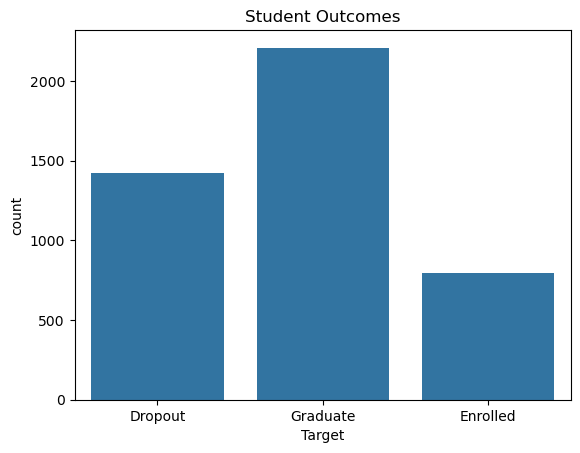

In [350]:
sns.countplot(
    data=df,
    x="Target")

plt.title("Student Outcomes")

The above Target outcome shows a balanced result, with 2,198 Graduates and 1,416 Dropouts, we also had 788 enrolled
Graduates were the largest category, showing that course completions were the most common
Although a large dropout rate may require further analysis

Text(0.5, 1.0, 'Student maritial status')

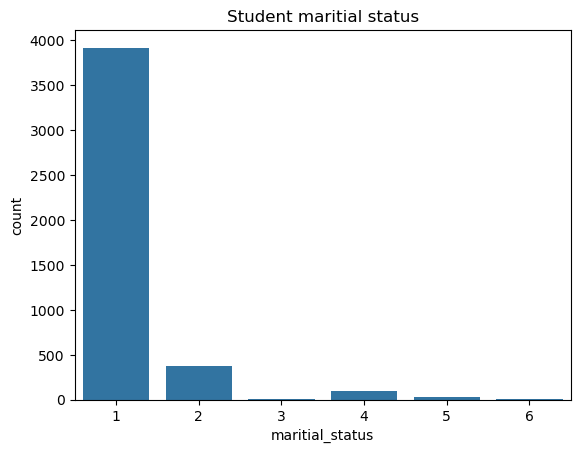

In [351]:
sns.countplot(
    data=df,
    x="maritial_status")

plt.title("Student maritial status")

Text(0.5, 1.0, 'Students by age range')

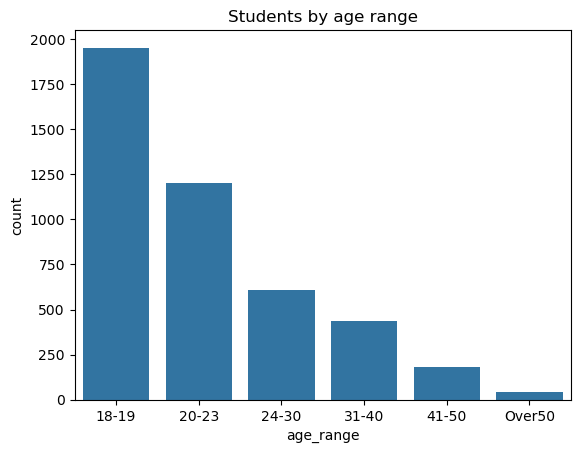

In [352]:
sns.countplot(
    data=df,
    x="age_range")

plt.title("Students by age range")

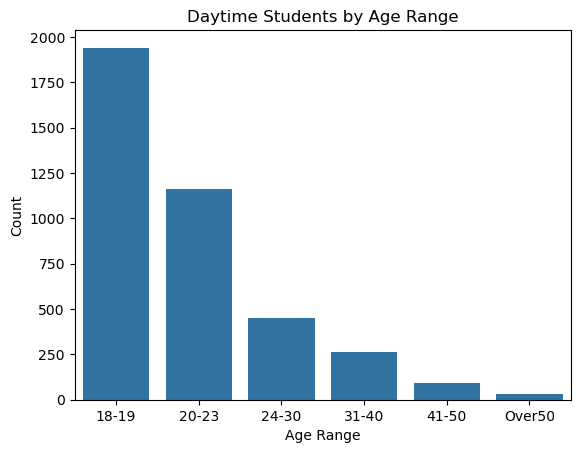

In [353]:
sns.countplot(
    data=df[df["course_time"] ==  1],
    x="age_range"
)

plt.title("Daytime Students by Age Range")
plt.xlabel("Age Range")
plt.ylabel("Count")
plt.show()

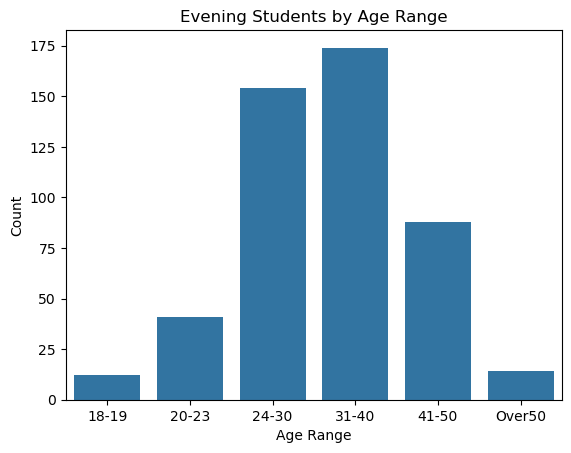

In [354]:
sns.countplot(
    data=df[df["course_time"] ==  0],
    x="age_range"
)

plt.title("Evening Students by Age Range")
plt.xlabel("Age Range")
plt.ylabel("Count")
plt.show()

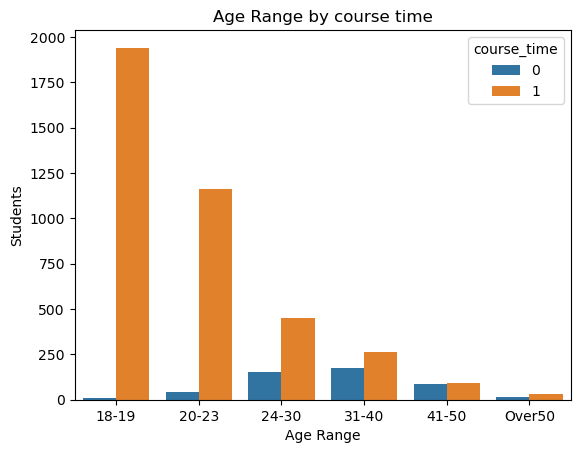

In [355]:
sns.countplot(
    data=df,
    x="age_range",
    hue="course_time"
)

plt.title("Age Range by course time")
plt.xlabel("Age Range")
plt.ylabel("Students")
plt.show()

#### Chart analysis
We can see from the above charts that younger students dominate the daytime courses, particularly in the 18-19 and 20-23 age ranges.  
Attendance of evening courses have more of an uptake with the older students.  This is to be expected given evening classes would generally be more part time for working adults

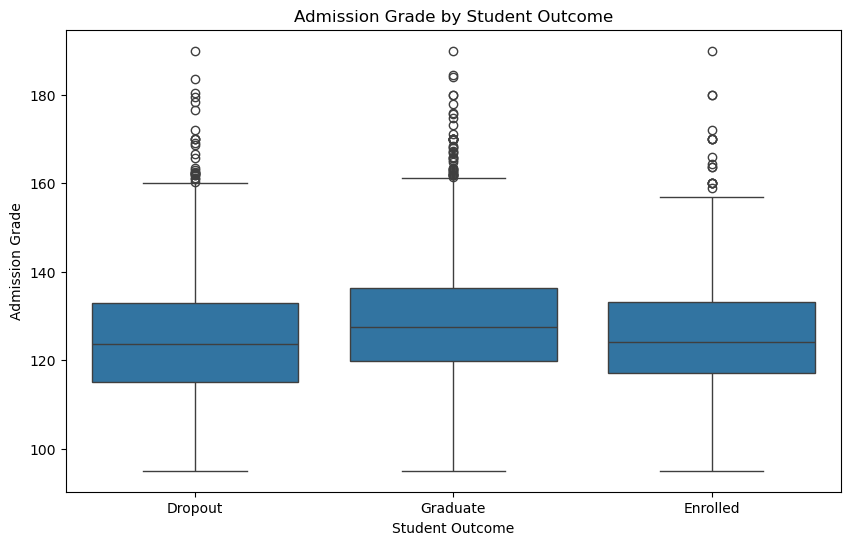

In [356]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["Target"],
    y= df["admission_grade"]
)
   

plt.title("Admission Grade by Student Outcome" )
plt.xlabel("Student Outcome")
plt.ylabel("Admission Grade")

plt.show()

#### Admission Grade Boxplot Analysis
The above boxplot would suggest that students with higher admission grades tended to have higher graduation rates.  
However the overlap detween groups indicates that admission grades alone does not fully explain outcomes

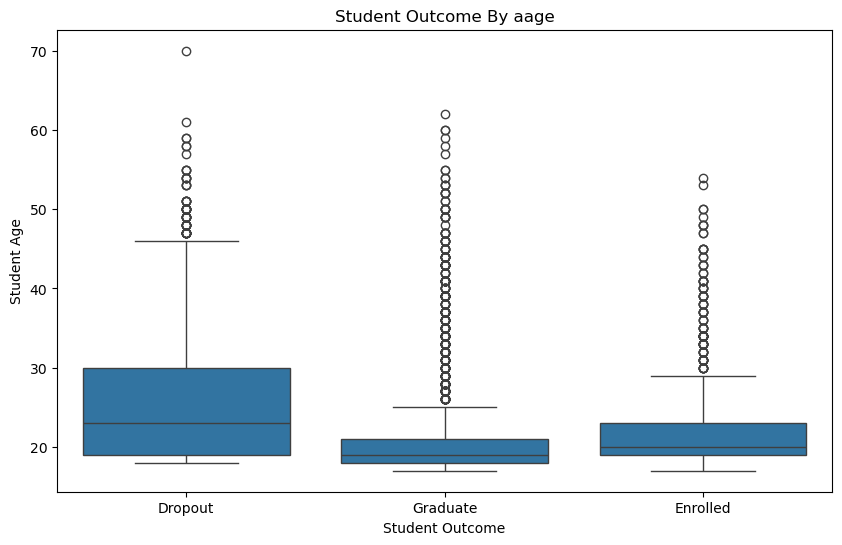

In [357]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["Target"],
    y= df["enrollment_age"]
)
   

plt.title("Student Outcome By aage" )
plt.xlabel("Student Outcome")
plt.ylabel("Student Age")

plt.show()

#### Enrollment Age Boxplot Analysis
The above boxplot suggests Graduates tend to be slightly younger than those who dropped out.  
Older students have a large variation in outcomes, this may be due to other committments outside of education

#### Scatterplot Analysis
There does not appear to be a strong linear relationship to enrollment age and admission grade.  
However there is a larger concentration of graduates appearing with higher admission grades, suggesting higher admission grades leads to a higher chance of graduating

<Axes: xlabel='enrollment_age', ylabel='admission_grade'>

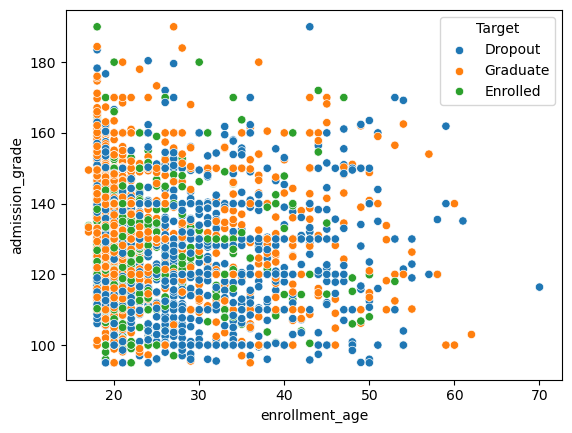

In [358]:
sns.scatterplot(
    data = df,
    x= "enrollment_age",
    y = "admission_grade",
    hue = "Target"
)

### Correlation

In [359]:
df_new = df[
    ["course_no",
     "enrollment_age", 
     "1st_sem_evaluation", 
     "2nd_sem_evaluation", 
     "1st_sem_grade",
     "2nd_sem_grade",
     "application_mode",
     "gender",
     "international",
     "tuition_paid",
     "unemployed_rate",
     "maritial_status"
     
    ] 
    ].copy()

In [360]:
corr_matrix = df_new.corr(numeric_only=True)
corr_matrix

,course_no,enrollment_age,1st_sem_evaluation,2nd_sem_evaluation,1st_sem_grade,2nd_sem_grade,application_mode,gender,international,tuition_paid,unemployed_rate,maritial_status
course_no,1.000000,0.043014,0.272811,0.278672,0.389375,0.348766,0.065290,-0.099333,-0.026770,0.018349,0.007091,0.046912
enrollment_age,0.043014,1.000000,0.139898,0.056257,-0.156571,-0.173418,0.516256,0.148961,-0.007111,-0.177746,0.024870,0.522721
1st_sem_evaluation,0.272811,0.139898,1.000000,0.778863,0.418061,0.355004,0.226005,-0.021334,0.012543,0.027375,0.061545,0.058030
2nd_sem_evaluation,0.278672,0.056257,0.778863,1.000000,0.487259,0.453374,0.167901,-0.041789,-0.004399,0.063088,0.045808,0.022784
1st_sem_grade,0.389375,-0.156571,0.418061,0.487259,1.000000,0.837173,-0.117856,-0.189431,0.006319,0.250275,0.014772,-0.059803
2nd_sem_grade,0.348766,-0.173418,0.355004,0.453374,0.837173,1.000000,-0.115719,-0.199065,0.001453,0.296281,0.001423,-0.071519
application_mode,0.065290,0.516256,0.226005,0.167901,-0.117856,-0.115719,1.000000,0.159394,0.003527,-0.135668,0.089188,0.264202
gender,-0.099333,0.148961,-0.021334,-0.041789,-0.189431,-0.199065,0.159394,1.000000,-0.026415,-0.104958,0.022195,-0.014738
international,-0.026770,-0.007111,0.012543,-0.004399,0.006319,0.001453,0.003527,-0.026415,1.000000,-0.044054,-0.010015,-0.027905
tuition_paid,0.018349,-0.177746,0.027375,0.063088,0.250275,0.296281,-0.135668,-0.104958,-0.044054,1.000000,0.014487,-0.086882


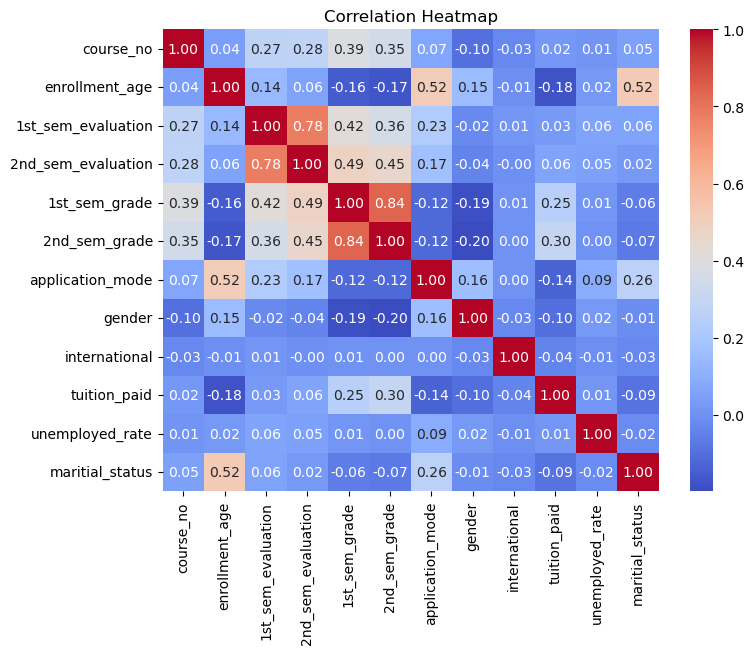

In [361]:
# create a seaborn heatmap
plt.figure(figsize=(8,6) )

sns.heatmap(
    corr_matrix,  
    annot=True,   
    cmap="coolwarm",  
    fmt=".2f" )      

plt.title("Correlation Heatmap")

plt.show()

### Correlation  analysis

Tuition paid has a positive correlation to 1st Semester and 2nd semester grades, indicating that fullly paying for a course may be a positive driving factor in grading.  
Notice also the strong positive correlation in 1st and 2nd semester grades along with evaluation

In [362]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 45 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   maritial_status          4424 non-null   Int64   
 1   application_mode         4424 non-null   Int64   
 2   application_order        4424 non-null   Int64   
 3   course_no                4424 non-null   Int64   
 4   course_time              4424 non-null   int64   
 5   previous_qual            4424 non-null   int64   
 6   previous_grade           4424 non-null   float64 
 7   nacionality              4424 non-null   Int64   
 8   mothers_qual             4424 non-null   int64   
 9   fathers_qual             4424 non-null   Int64   
 10  mothers_occupation       4424 non-null   Int64   
 11  fathers_occupation       4424 non-null   Int64   
 12  admission_grade          4424 non-null   float64 
 13  Displaced                4424 non-null   object  
 14  special_

In [363]:
len(df)

4424

#### Create a Pivot Table to show Target by course name

In [364]:
# create a pivot table
pivot = pd.pivot_table (
    df,
    values="enrollment_age",
    index=["course_name", "gender"], # Further group course name by gender
    columns="Target",
    aggfunc="count",
    fill_value=0,
    margins = True
)
pivot

Target                                       Dropout  Enrolled  Graduate   All
course_name                          gender                                   
Advertising and Marketing Management 0            41        26        78   145
                                     1            54        22        46   122
Agronomy                             0            17        10        34    61
                                     1            69        27        53   149
Animation and Multimedia Design      0            36        15        47    98
                                     1            46        22        49   117
Basic Education                      0            81        47        55   183
                                     1             4         3         2     9
Biofuel Production Technologies      0             1         1         1     3
                                     1             7         2         0     9
Communication Design                 0            22        23        85   130
                                     1            29        19        48    96
Equinculture                         0            38        14        27    79
                                     1            39         7        15    61
Informatics Engineering              0             6         1         0     7
                                     1            86        63        14   163
Journalism and Communication         0            60        21       135   216
                                     1            41        13        61   115
Management                           0            54        63       101   218
                                     1            80        44        37   161
Management (evening attendance)      0            54        38        40   132
                                     1            82        16        38   136
Nursing                              0            81        76       460   617
                                     1            37        24        88   149
Oral Hygiene                         0            21        14        32    67
                                     1            12         3         4    19
Social Service                       0            43        39       227   309
                                     1            22         3        21    46
Social Service (evening attendance)  0            54        16       103   173
                                     1            17         5        20    42
Tourism                              0            52        17        83   152
                                     1            44        24        32   100
Unknown                              0             0         0         1     1
                                     1             1         1         0     2
Veterinary Nursing                   0            59        66       152   277
                                     1            31         9        20    60
All                                             1421       794      2209  4424

#### Pivot Table Analysis
We can see above that Nursing was the most popular of the course offerings, With 616 Females and 149 Males registering for Nursing.  
Nursing had 459 Female Graduates 74.5% and 88 Male Graduates = 59.06%, resulting in an overall 71.5% Graduation rate in nursing
Biofuel Production Technologies was the least popular course, with only 1 Graduated from 12 registrations

In [365]:
# create a pivot table by course attendence time (day / Evening) 
pivot_attend = pd.pivot_table (
    df,
    values="enrollment_age", # used as a count
    index=["course_time"],
    columns="Target",
    aggfunc="count",
    fill_value=0,
    margins = True
)
pivot_attend

Target,Dropout,Enrolled,Graduate,All
course_time,,,,
0,207,75,201,483
1,1214,719,2008,3941
All,1421,794,2209,4424


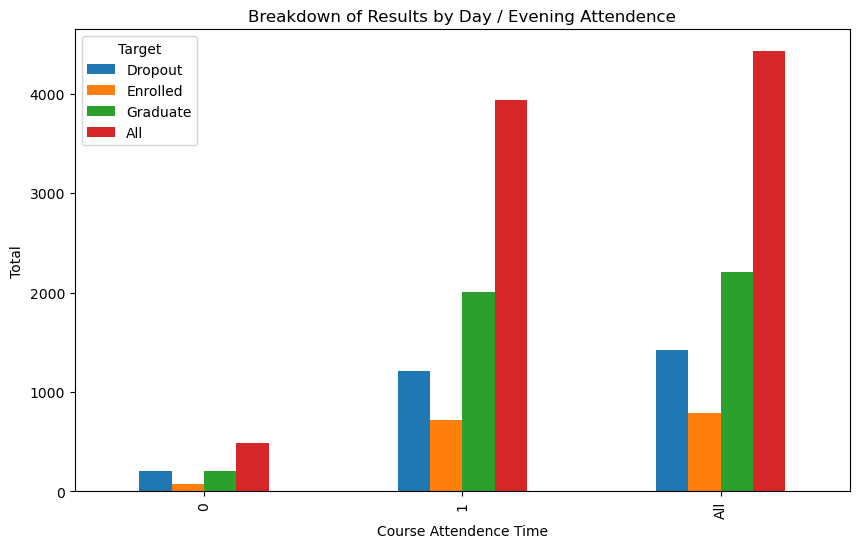

In [366]:
pivot_chart = pivot_attend.drop(
    index="Total",
    errors="ignore").drop(
    columns="Total",
    errors="ignore")

pivot_chart.plot(
    kind="bar",
    figsize=(10,6))

plt.title("Breakdown of Results by Day / Evening Attendence")
plt.xlabel("Course Attendence Time")
plt.ylabel("Total")


plt.show()

#### Analysis of the above chart and pivot table
We can see that although only 2 courses were offered in the evening. 
Graduates from those course we quite low with 201 Graduates from 483 registered = 41.61% Graduation rate
Daytime course have 2008 Graduates from 3941 registered = 50.95% Graduation rate

#### Create a Frequency table by scholarship holders

In [367]:
pd.crosstab(
    [ df["scholarship_holder"], df["course_time"] ], # show as rows Yes, No
    df["Target"], # shows as columns, outcome
    normalize = "index" # show the values as percentage
).mul(100).round(2) # multiply by 100 and round to 2, to give a better overall % value

Target                          Dropout  Enrolled  Graduate
scholarship_holder course_time                             
0                  0              47.73     15.27     36.99
                   1              37.41     20.65     41.95
1                  0              10.94     17.19     71.88
                   1              12.27     11.50     76.23

We can see from above Pandas Frequency Table that scholarship holders (1) have a 76.23% Graduate rate for Daytime courses (1)
And only a 12.27% Dropout rate for Daytime courses.  
Scholarship Holders also have a 71.88% Graduation for Evening Courses.  
This suggests that scholarship holders attending Daytime courses achieved the highest graduation rates

#### Create a GroupBy Table to show 1st Semester grades
#### Breakdown the results by course_name and Target outcome

In [368]:
df.groupby(
    ["course_name", "Target"]) ["1st_sem_grade"].mean().round(2)

course_name                           Target  
Advertising and Marketing Management  Dropout      8.56
                                      Enrolled    12.28
                                      Graduate    13.09
Agronomy                              Dropout      7.18
                                      Enrolled    10.63
                                      Graduate    13.43
Animation and Multimedia Design       Dropout      0.74
                                      Enrolled     3.04
                                      Graduate     2.83
Basic Education                       Dropout      9.64
                                      Enrolled    12.49
                                      Graduate    13.31
Biofuel Production Technologies       Dropout      7.91
                                      Enrolled    13.07
                                      Graduate    13.18
Communication Design                  Dropout      9.19
                                      Enrolled    11.84
 

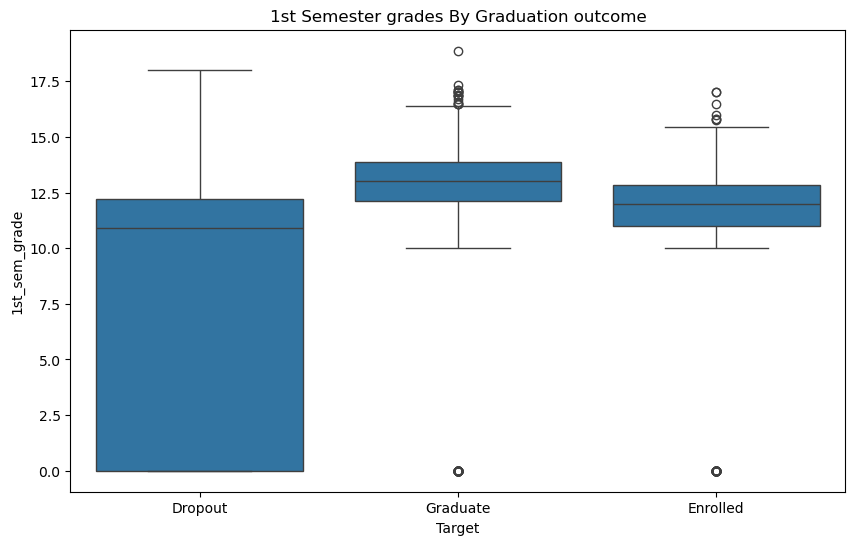

In [369]:
plt.figure(figsize=(10,6))
sns.boxplot(
    data=df,
    x="Target",
    y="1st_sem_grade"
)

plt.title ("1st Semester grades By Graduation outcome")
plt.show()

Analysis of 1st Semester Grades shows that the higher the grade at end of 1st semester, the more likely the student will qualify.
Take for example the most popular course "Nursing".  Graduates in Nursing have a mean score of 13.51 as opposed to 7.75 for Dropouts.  
This suggests that 1st Semester grades have a high influence on graduatiuon outcomes
See above Boxplot for a visualisation

## The curse of Dimensionality

The curse of dimensionality refers to problems that may arise due when a dataset, contains a large number of features, as the number of dimensions increase, observations become more spread out and the distance between points become less meaningful.
This may make it difficult to find patterns or reltionships within the data and could have a negative impact on machine learning models, as they become more complex and prone to overfitting.
Although Machine Learning models excel at analysing many dimensions, the more dimensions we add, then the more processing power required, to make meaningful models.
Another aspect, if the data is too simple, then the models can become biased and output an underfitting result. Whereas, if the data is too complex, it can result in a high variance in the data and output an overfitting result.

This is where Principal Component Analysis (PCA) becomes valuable.  The purpose of PCA is Dimension Reduction by transforming the original variables into a smaller set of components and still retain the majority of the dataset variance.  
By reducing dimensionality, the analysis becomes more efficient and helps reduce any risk of overfitting.  This streamlined dataset can act as the data for the machine models to train on.
In our current Student dataset, there were 37 variables, Several contained overlapping and redundant data. This can cause an increase in the dimensionality without really improving analysis

### PCA
#### import sklearn libraries

In [370]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

In [371]:
No_Columns = df.shape[1]
No_Columns

45

As PCA is sensitive to feature scales, the data must be standardised to have zero mean and unit variance, you need to decide the number of principal components to keep ie it can be an integer value or a percentage of variance
PCA requires numerical inputs, therefore only numeric variables were selected.  
the numeric variables will be standardised using StandardScaler

In [372]:
# select only the numeric codes
X = df.select_dtypes(include=[np.number])
num_rows = X.shape[0]
num_features = X.shape[1]

print(f" The number of rows: {num_rows} ")
print(f" The number of features selected for PCA was: {num_features} ")


 The number of rows: 4424 
 The number of features selected for PCA was: 35 


In [373]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


PCA has now taken 35 columns, as opposed to the 45 original columns

In [374]:
pca = PCA(n_components=0.995) 

X_pca = pca.fit_transform(X_scaled)

Check how much variance each principal component explains

In [375]:
print(f"The number of columns in the dataset was: {No_Columns} ")
print(f"The number of numeric columns in the dataset, prior to PCA was: {num_features} ")
print(f"The number of components retained after PCA was: {pca.n_components_} ")    
print(f"The percentage of Variance retained was: {pca.explained_variance_ratio_.sum()*100:.2f} %") 

The number of columns in the dataset was: 45 
The number of numeric columns in the dataset, prior to PCA was: 35 
The number of components retained after PCA was: 32 
The percentage of Variance retained was: 99.58 %


In [376]:
print(f"Variance Explained:  {pca.explained_variance_ratio_ }")

Variance Explained:  [0.18164042 0.09644001 0.06020902 0.05728381 0.05315807 0.0478081
 0.04496761 0.04341425 0.03646766 0.03517444 0.03105545 0.0286519
 0.02821375 0.02507873 0.02491285 0.02316396 0.02100039 0.02067571
 0.01795435 0.01635219 0.01521305 0.01326989 0.0129927  0.01184737
 0.0110065  0.00910832 0.00689419 0.00592928 0.00544821 0.00483226
 0.00298704 0.00265714]


The dataset currently had 45 variables, of which 35 were numeric and suitable for PCA.  
By applying PCA, the original numeric features were reduced  from 35 into 32 principal components, whilst still retaining 99.58% of the total variance

This showed that some variables contained overlapping information and I was able to reduce dimensionality, with minimal information loss.

#### Classification Model Testing

#### Create a map for Target Variable to convert to numeric

In [377]:
target_map = {
        "Dropout"  : 0,
        "Graduate" : 1,
        "Enrolled" : 2
   
    }

In [378]:
df["target_code"] = df["Target"].map(target_map)

In [379]:
df["target_code"].value_counts()

target_code
1    2209
0    1421
2     794
Name: count, dtype: int64

In [380]:
# Spliting the dataset into independent and dependent variables

# Use numeric variables only from the daatasett
X = df.select_dtypes(include=[np.number])

# Remove the target_code
X = X.drop(columns=["target_code"])


# Dependent variables (Target)
y = df["target_code"]



In [381]:
# Splitting the dataset into the Training set and Test set


# Split the dataset (X, y) into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.20, 
    random_state = 82)

# Display rows and columns
X_train.shape, X_test.shape

((3539, 35), (885, 35))

Training rows = 33539
Testing rows = 885

In [382]:
# Feature Scaling to bring the variable in a single scale


# Create an initialise an object sc by calling a method StandardScaler()
sc = StandardScaler()

# Train the model by calling a method fit_transform
X_train = sc.fit_transform(X_train)

# Store the transformed data into X_test
X_test = sc.transform(X_test)

In [383]:
# NB = Naive Bayes
# Gaussian = assumes the numeric variables follow a normal distribution

# Create an initialise an object "nb_model" by calling a method 'GaussianNB()'
nb_model = GaussianNB()

# Call fit() method for training the dataset
nb_model.fit(
    X_train,
    y_train)

,priors,None
,var_smoothing,1e-09


In [384]:
# Predicting the Test set results
y_pred = nb_model.predict(
    X_test)



In [385]:
# Check the actual and predicted value side by side
y_compare = np.vstack((y_test,y_pred)).T
# actual value on the left side and predicted value on the right hand side
# printing the top 20 values
y_compare[:20,:]

array([[1, 2],
       [0, 0],
       [0, 2],
       [1, 1],
       [1, 1],
       [0, 0],
       [1, 1],
       [2, 0],
       [1, 1],
       [2, 2],
       [1, 1],
       [2, 1],
       [1, 1],
       [1, 1],
       [2, 1],
       [0, 0],
       [2, 0],
       [1, 1],
       [1, 1],
       [0, 0]])

In [386]:
score = accuracy_score(
    y_test, 
    y_pred)


print(f"Accuray Score is : {score:.2%} ")

Accuray Score is : 68.36% 


A Naive Bayes classifier was developed on the original dataset.  The model returned an accuracy score of 68.36%.

This Correctly predicted almost 7/10 student outcomes.  This provides a baseline against the PCA transformed dataset, to be compared later.

In [387]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred)
)

              precision    recall  f1-score   support

           0       0.72      0.68      0.70       274
           1       0.74      0.83      0.78       462
           2       0.32      0.23      0.27       149

    accuracy                           0.68       885
   macro avg       0.59      0.58      0.58       885
weighted avg       0.66      0.68      0.67       885



From the above classification report, the model performed best by identifying the 0-Dropouts and 1-Graduates.  
Assessing Graduates, it returned a recall score of 83% and a f1 score of 78%.  

However, the accuracy score struggled with enrolled students (2) due to less overall students numbers listed as enrolled.

Overall the accuracy test scored highly with Graduates and Dropouts

#### Testing the PCA Dataset

In [388]:
pca = PCA(n_components=0.995)

X_train_pca = pca.fit_transform(
    X_train)

X_test_pca = pca.transform(
    X_test)

In [389]:
# Apply PCA to the Training Data
nb_model_pca = GaussianNB()

nb_model_pca.fit(
    X_train_pca,
    y_train)



,priors,None
,var_smoothing,1e-09


In [390]:
# Predicting the Test set results
y_pred_pca = nb_model_pca.predict(
    X_test_pca)


In [391]:
score_pca = accuracy_score(
     y_test, 
     y_pred_pca)


print(f"PCA Accuray Score is : {score_pca:.2%} ")

PCA Accuray Score is : 68.36% 


The Data dictionary states: "Target. The problem is formulated as a three category classification task (dropout, enrolled, and graduate) at the end of the normal duration of the course".  

I created the target_code and encoded it into 3 numerical classes , where 0 = Dropout, 1= Graduate and 2 = enrolled

The PCA dataset achieved an accuracy score of 68.36%.  

Despite PCA reducing the number of numerical columns from 35 to 32, the model maintained the same classification accuracy as the original dataset

This suggests that PCA removed redundant data and retained the important patterns that we required for classification modelling

### References: 
CCT College Dublin (2026) Data Preparation Module Notes. Available via Moodle 
(Accessed: 18 October 2026)

CCT College Dublin (2026) Machine Learning Module Notes. Available via Moodle 
(Accessed: 26 October 2026)

CCT College Dublin (2026) Stastical Techniques Module Notes. Available via Moodle 
(Accessed: 22 October 2026)

Pierian Data (2026) Python for Machine Learning & Data Science Masterclass. Available at: https://www.udemy.com
(Accessed: 8 October 2026)

Maven Analytics (2026) Machine Learning & Data Science: The Complete Visual Guide. Available at https://www.udemy.com
(Accessed 15 October 2026)

Maven Analytics (2026) Python Data Science: Classification Modelling. Available at https://www.udemy.com
(Accessed 21 October 2026)
GeeksforGeeks (2025) Implementing PCA in Python with Scikit-Learn Available at: https://www.geeksforgeeks.org/machine-learning/implementing-pca-in-python-with-scikit-learn/
(Accessed (24/10/2026)

CodeGenes.net (2026)  https://www.codegenes.net/blog/batch-convert-columns-to-numeric-type/
Accessed (30/10/2026)


In [392]:
df.to_csv("student_data_v2_updated.csv", index=False)

End Of Analysis